## Inicialização

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.resnet import preprocess_input

## EDA

In [75]:

path = 'data/faces/'
labels = pd.read_csv(path + 'labels.csv')

train_datagen = ImageDataGenerator(rescale=1./255)

train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory='data/final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=12345)


Found 7591 validated image filenames.


In [76]:
display(labels.head())

,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


#### Verificando o tamanho do conjunto de dados

In [77]:
print('Quantidade de imagens', labels.shape[0])
print('Quantidade de colunas ', labels.shape[1])

Quantidade de imagens 7591
Quantidade de colunas  2


#### Carregando as informações gerais

In [78]:
labels.info()

<class 'pandas.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   file_name  7591 non-null   str  
 1   real_age   7591 non-null   int64
dtypes: int64(1), str(1)
memory usage: 192.9 KB


In [79]:
display(labels['real_age'].describe())

count    7591.000000
mean       31.201159
std        17.145060
min         1.000000
25%        20.000000
50%        29.000000
75%        41.000000
max       100.000000
Name: real_age, dtype: float64

### Conclusões

O conjunto de dados possui 7.591 registros, sem valores ausentes nas colunas analisadas. As idades variam de 1 a 100 anos, com média de 31 anos e mediana de 29 anos. A distribuição apresenta uma diversidade considerável de faixas etárias, sendo adequada para iniciar o desenvolvimento de um modelo de estimativa de idade.

#### Histograma sobre a distribuição das idades

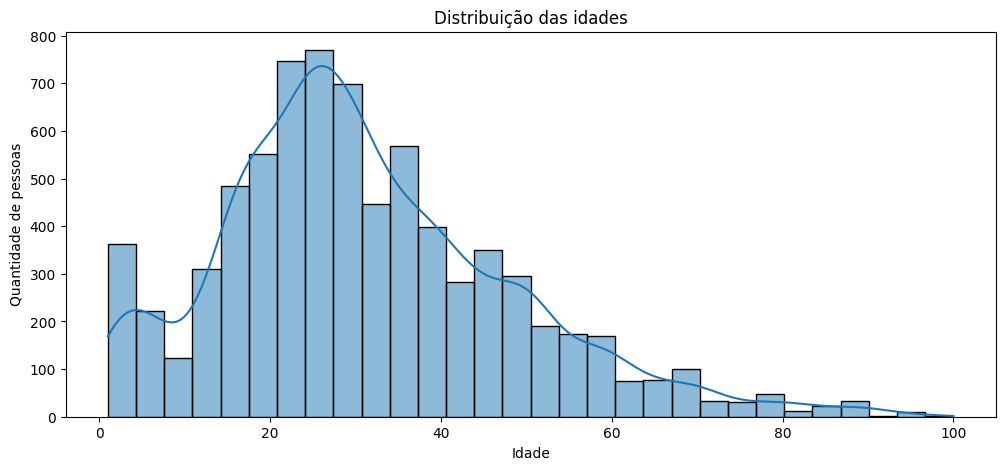

In [80]:
plt.figure(figsize=(12,5))

sns.histplot(labels['real_age'], bins=30, kde=True)

plt.title('Distribuição das idades')
plt.xlabel('Idade')
plt.ylabel('Quantidade de pessoas')

plt.show()

#### imprimindo as primeiras 15 fotos

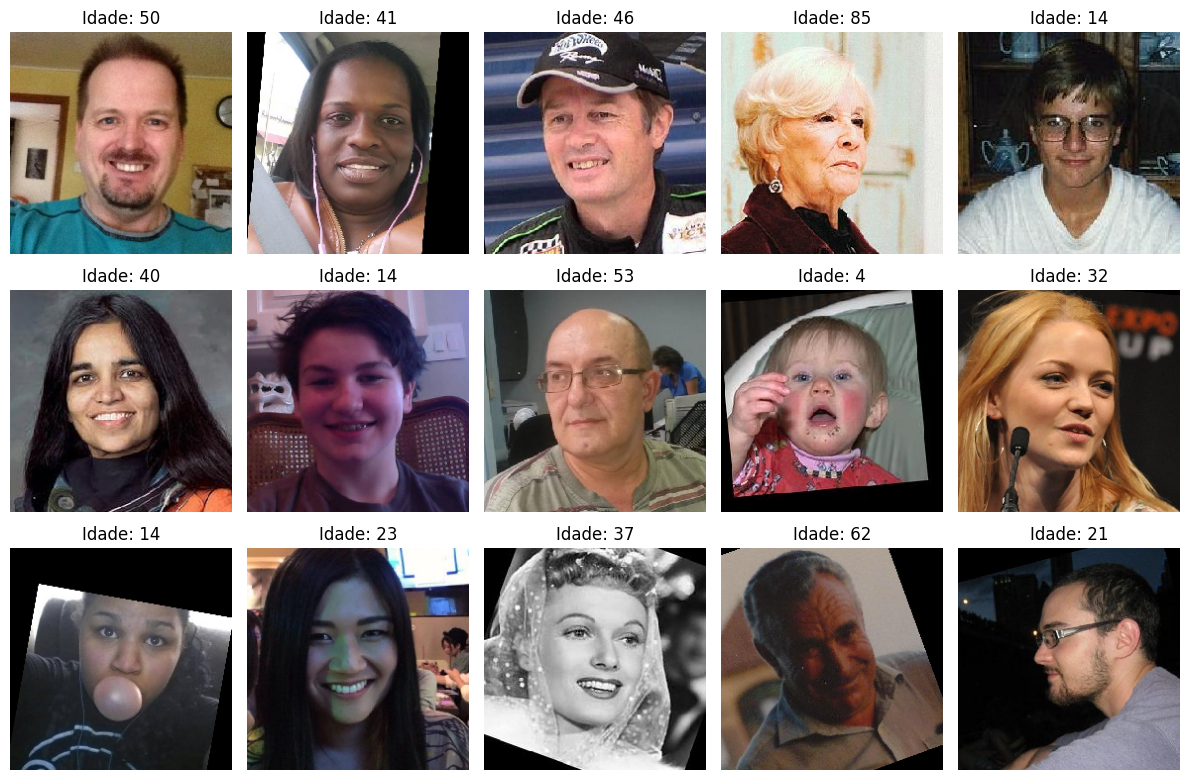

In [81]:
features, target = next(train_gen_flow)

fig = plt.figure(figsize=(12, 8))

for i in range(15):
    fig.add_subplot(3, 5, i + 1)

    plt.imshow(features[i])
    plt.title(f'Idade: {target[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [83]:
print(labels.shape)
print(labels.head())
print(labels['file_name'].head())

(7591, 2)
    file_name  real_age
0  000000.jpg         4
1  000001.jpg        18
2  000002.jpg        80
3  000003.jpg        50
4  000004.jpg        17
0    000000.jpg
1    000001.jpg
2    000002.jpg
3    000003.jpg
4    000004.jpg
Name: file_name, dtype: str


## Modelagem

In [84]:
def load_data(path, subset='training'):

    labels = pd.read_csv(path + 'faces/labels.csv')

    datagen = ImageDataGenerator(
        validation_split=0.25,
        preprocessing_function=preprocess_input
    )

    gen_flow = datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset=subset,
        seed=12345
    )

    return gen_flow

In [85]:
def create_model(input_shape):

    backbone = ResNet50(input_shape=input_shape, weights='imagenet', include_top=False)

    #Congelando a rede
    backbone.trainable = False

    model = Sequential([backbone, GlobalAveragePooling2D(), Dense(1, activation='relu')])

    optimizer = Adam(learning_rate=0.0001)

    model.compile(
        optimizer=optimizer,
        loss='mean_squared_error',
        metrics=['mae']
    )

    return model


In [86]:
def train_model(model, train_data, test_data, batch_size=None, epochs=5):

    model.fit(
        train_data,
        validation_data=test_data,
        epochs=epochs,
        steps_per_epoch=len(train_data),
        validation_steps=len(test_data),
        verbose=2
    )

    return model

### Resultado

Execute o treinamento na célula abaixo e mantenha a saída visível.

In [87]:
path =  'data/'

train_data = load_data(path, subset='training')
test_data = load_data(path, subset='validation')

model = create_model((224, 224, 3))

model = train_model(model, train_data, test_data)

Found 5694 validated image filenames.
Found 1897 validated image filenames.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/5
178/178 - 661s - 4s/step - loss: 895.6813 - mae: 24.8823 - val_loss: 534.4186 - val_mae: 18.1907
Epoch 2/5
178/178 - 362s - 2s/step - loss: 477.4174 - mae: 16.7095 - val_loss: 354.2447 - val_mae: 14.2646
Epoch 3/5
178/178 - 291s - 2s/step - loss: 362.0442 - mae: 14.3986 - val_loss: 318.1680 - val_mae: 13.7038
Epoch 4/5
178/178 - 279s - 2s/step - loss: 333.1630 - mae: 13.9614 - val_loss: 306.3924 - val_mae: 13.6107
Epoch 5/5
178/178 - 272s - 2s/step - loss: 319.6672 - mae: 13.7665 - val_loss: 295.4802 - val_mae: 13.4382


#### Conclusão

O modelo foi treinado utilizando a arquitetura ResNet50 com pesos pré-treinados no ImageNet, mantendo a rede convolucional congelada e adicionando as camadas GlobalAveragePooling2D e Dense para realizar a previsão da idade.

Ao longo das cinco épocas, foi possível observar uma redução progressiva dos erros de treinamento e validação. Ao final, o modelo alcançou um MAE de aproximadamente 13,48 anos no conjunto de validação, indicando que as previsões apresentam um erro absoluto médio de cerca de 13,48 anos em relação às idades reais.

Os resultados demonstram que o modelo conseguiu aprender padrões relevantes nas imagens e melhorar seu desempenho durante o treinamento, sem apresentar sinais evidentes de overfitting nas cinco épocas realizadas.

##### Conclusão geral do projeto

O projeto teve como objetivo desenvolver um modelo de Deep Learning capaz de estimar a idade de pessoas a partir de fotografias, utilizando técnicas de visão computacional.

Durante o desenvolvimento, foi realizada a análise dos dados, o carregamento e pré-processamento das imagens, a separação dos conjuntos de treinamento e validação e a construção de um modelo baseado na arquitetura ResNet50, utilizando Transfer Learning.

A utilização de uma rede pré-treinada permitiu aproveitar características visuais previamente aprendidas, adaptando o modelo para uma tarefa de regressão, na qual a saída corresponde à idade estimada da pessoa.

Ao final do treinamento, o modelo alcançou um MAE de 13,48 anos no conjunto de validação. Embora tenha apresentado uma evolução consistente, esse resultado indica que ainda existe margem para melhorar a precisão das estimativas.

O desenvolvimento deste projeto permitiu aplicar conceitos de Redes Neurais Convolucionais, Transfer Learning, pré-processamento de imagens e avaliação de modelos de Deep Learning, demonstrando como essas técnicas podem ser utilizadas em problemas reais de visão computacional.